# Road accidents in France and in Haut-Rhin, 2019–2024
Guided tour of the analysis. Every table comes from a SQL query on the DuckDB database built by `src/build_db.py`; every chart is produced by a function of `src/analysis.py`.

Data: ONISR national road-accident file (BAAC), INSEE population estimates. Scope: metropolitan France.

In [1]:
import sys; sys.path.insert(0, '../src')
from IPython.display import Image
import pandas as pd; pd.set_option('display.precision', 3)
from analysis import *
from model import fit, fig_odds

## 0. Can we trust the data?
Share of missing values on the fields we use, then our yearly death counts compared with the official ONISR figures.

In [2]:
data_quality()

,field,missing_%
0,Accident: GPS coordinates,0.00
1,Accident: hour,0.00
2,Accident: weather,0.01
3,Place: speed limit (valid 10-130),2.23
4,Person: severity,0.05
5,Person: age,1.50
6,Person: sex,1.43
7,Person: travel mode,0.53


In [3]:
validation_vs_onisr()

,year,killed_ours,killed_onisr
0,2019,3244,3244.0
1,2020,2541,2541.0
2,2021,2944,2944.0
3,2022,3267,3267.0
4,2023,3167,3167.0
5,2024,3193,NaN


Our counts match the official figures exactly for 2019–2023 (2024 was not yet published as a final figure when this was written), so the cleaning keeps every accident.

## 1. Trend
Accidents fell during the 2020 lockdowns and have not returned to 2019 levels; deaths have.

In [4]:
tr = yearly_trend(); tr

,year,accidents_fr,killed_fr,accidents_68,killed_68
0,2019,56016,3244,437,25
1,2020,45121,2541,317,19
2,2021,53540,2944,373,29
3,2022,52380,3267,319,30
4,2023,51641,3167,367,36
5,2024,51058,3193,351,27


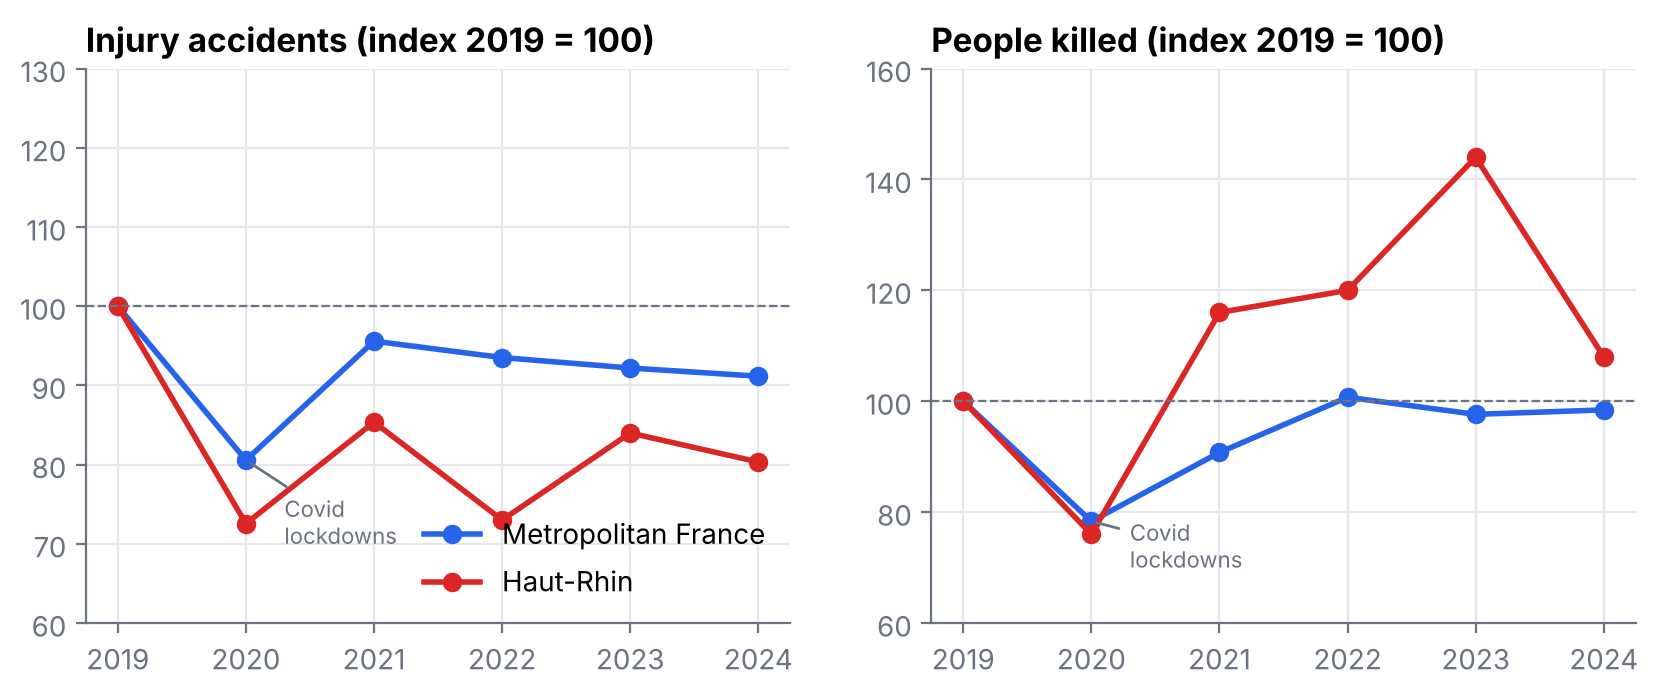

In [5]:
fig_trend(tr); Image('../figures/01_trend.png')

Haut-Rhin counts are small (20–36 deaths a year), so year-to-year swings are mostly noise.

## 2. When
Busiest at the evening rush hour; deadliest between 3 and 6 a.m. (about 11% of accidents fatal, vs 4.5–5.5% during the day).

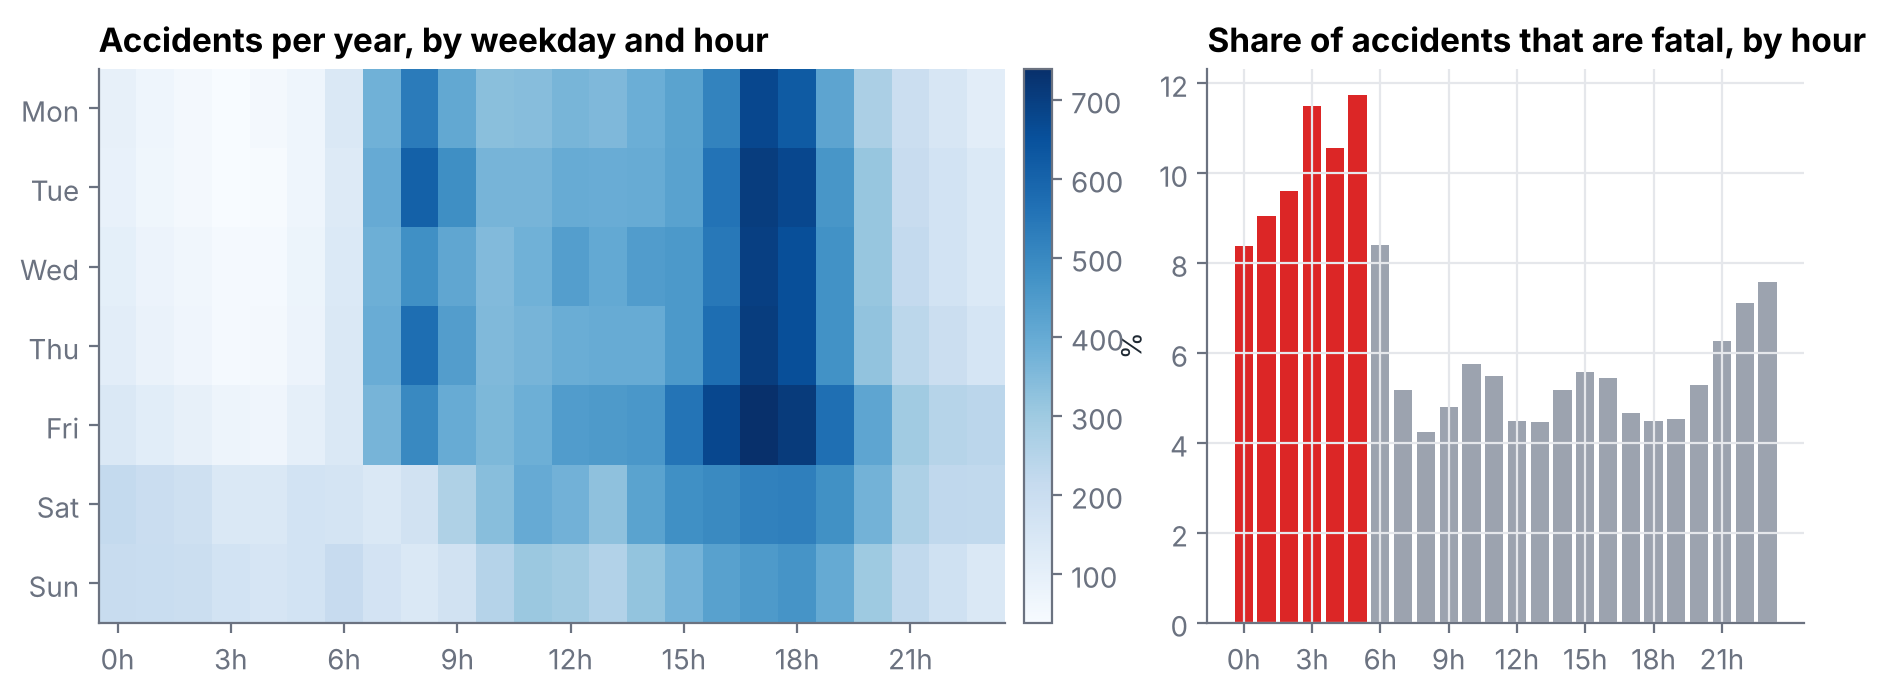

In [6]:
hw = hour_weekday(); fig_when(hw); Image('../figures/02_when.png')

## 3. Who

In [7]:
km = killed_by_mode(); fig_modes(km)

,2019,2024,change_%
mode,,,
Car,1658,1571,-5.0
Motorcycle,615,597,-3.0
Pedestrian,482,454,-6.0
Bicycle,172,192,12.0
E-scooter,11,47,327.0
E-bike,15,32,113.0


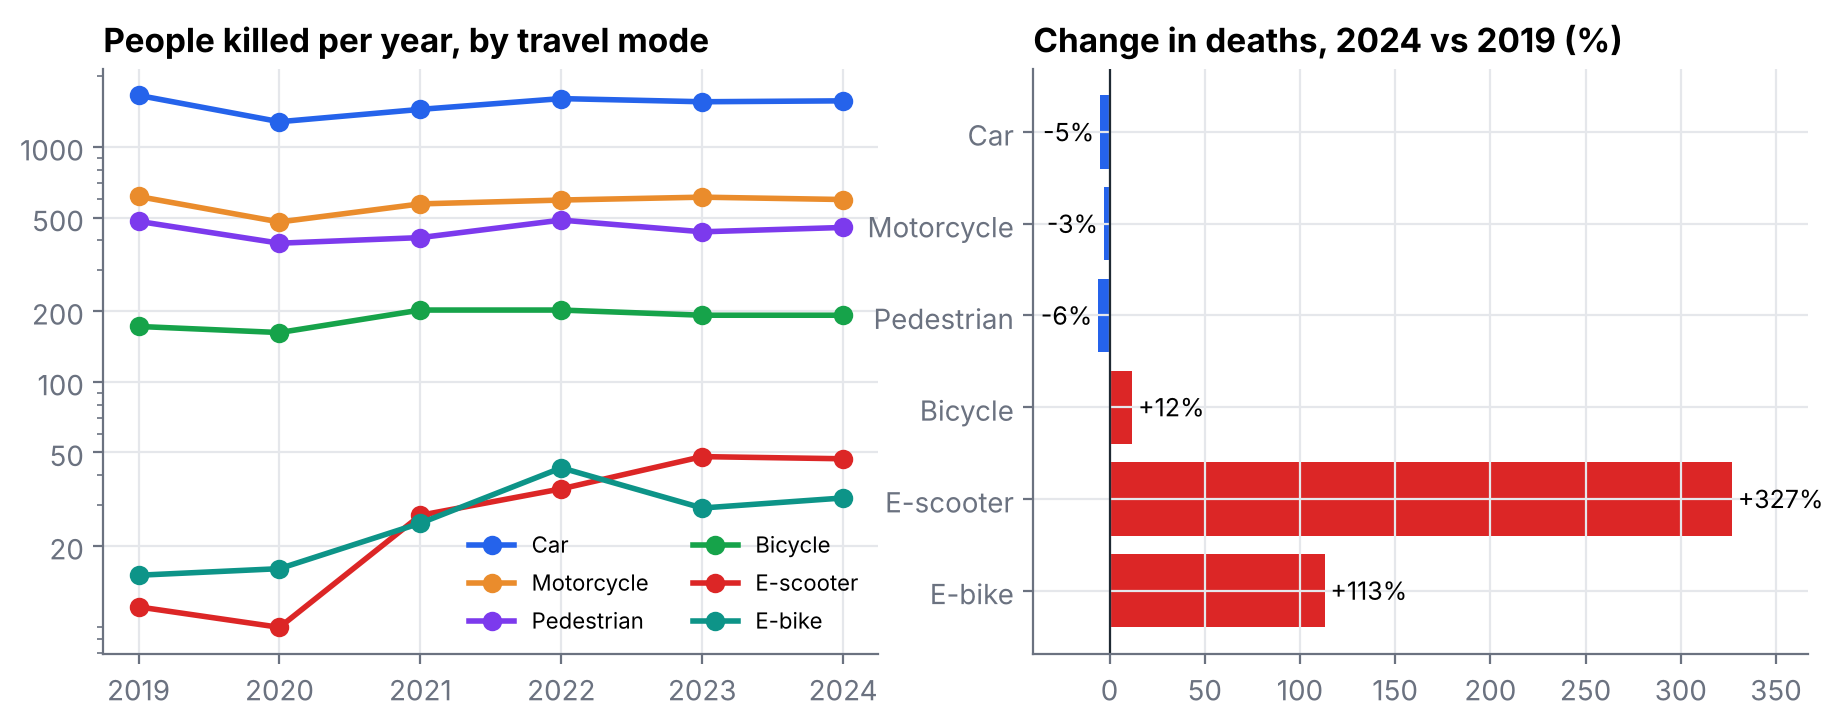

In [8]:
Image('../figures/03_modes.png')

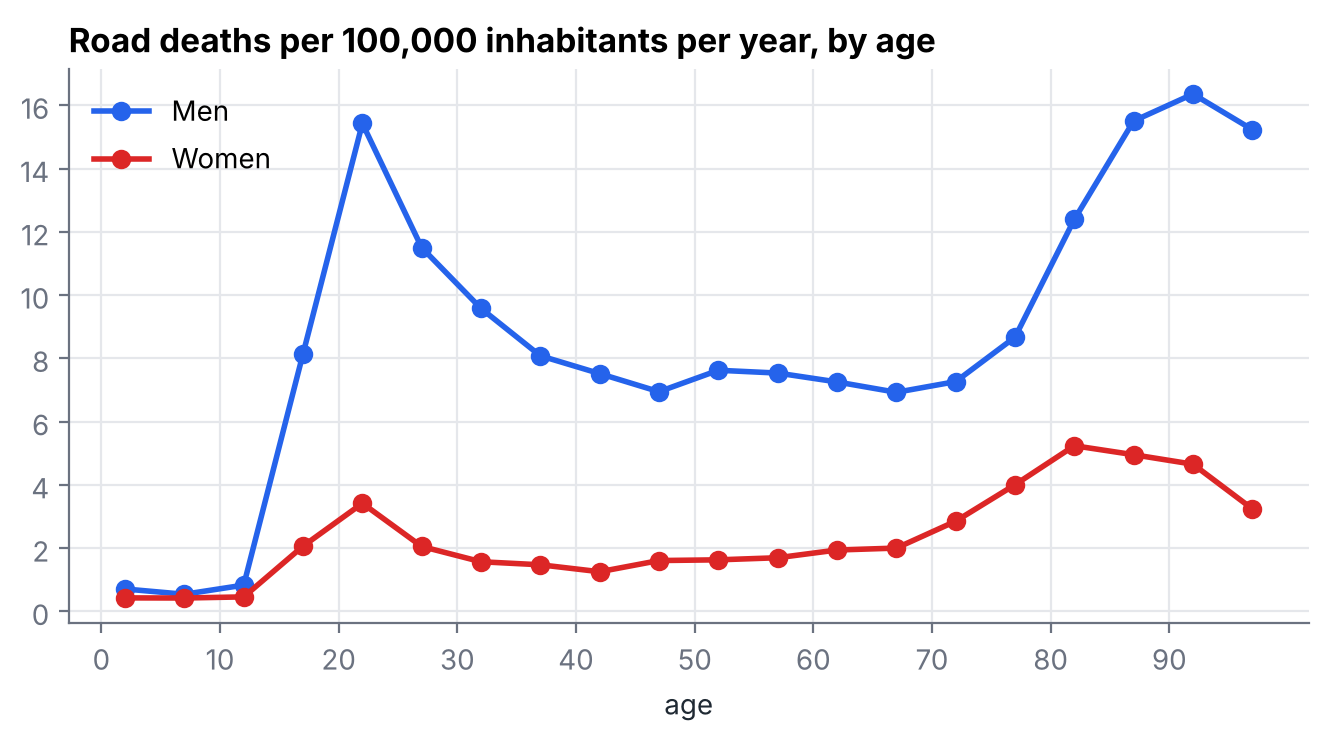

In [9]:
ag = killed_rate_by_age(); fig_age(ag); Image('../figures/04_age.png')

Young men (20–24) and people over 80 have the highest death rates.

## 4. Where

In [10]:
dep = by_department(); dep.head(10)

,dep,pop,killed_per_year,acc_per_year,killed_per_million,rank_safest
0,92,1.642e+06,22.667,2394.500,13.804,1
1,94,1.427e+06,21.833,2297.167,15.303,2
2,93,1.683e+06,27.167,2765.833,16.144,3
3,75,2.103e+06,37.667,4905.000,17.914,4
4,95,1.274e+06,27.333,865.167,21.448,5
5,78,1.462e+06,37.000,676.667,25.316,6
6,91,1.316e+06,34.000,1349.833,25.835,7
7,69,1.921e+06,54.500,2119.167,28.370,8
8,59,2.607e+06,86.333,972.333,33.120,9
9,67,1.168e+06,39.333,636.500,33.664,10


In [11]:
dep[dep.dep == '68']

,dep,pop,killed_per_year,acc_per_year,killed_per_million,rank_safest
10,68,769231.0,27.667,360.667,35.967,11


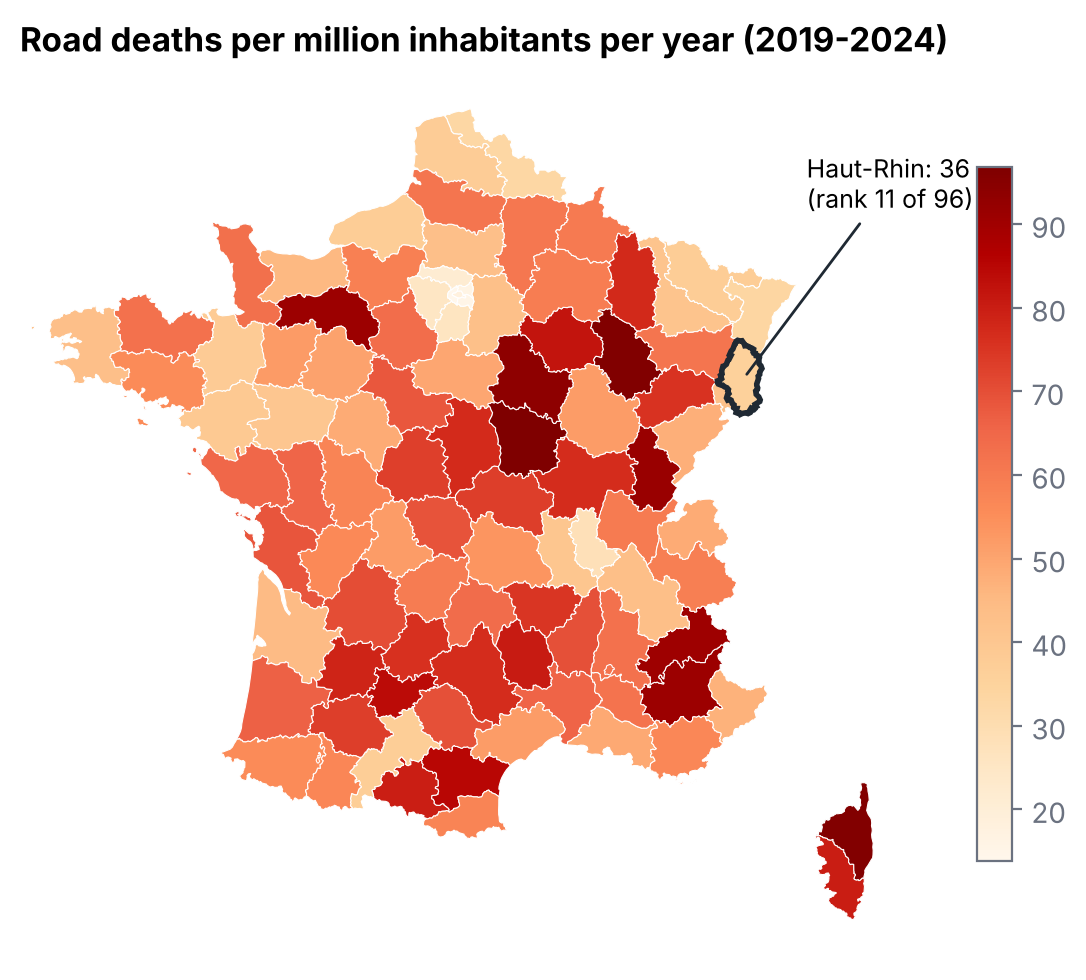

In [12]:
fig_map(dep); Image('../figures/05_map_departments.png')

In [13]:
profile_68_vs_france()

area,Haut-Rhin,France (other depts)
in_town,0.533,0.639
at_night,0.241,0.265
on_motorway,0.091,0.098
with_motorcycle,0.189,0.226
with_bike_or_escooter,0.167,0.138
with_pedestrian,0.148,0.164
fatal,0.072,0.056
killed_per_accident,0.077,0.059


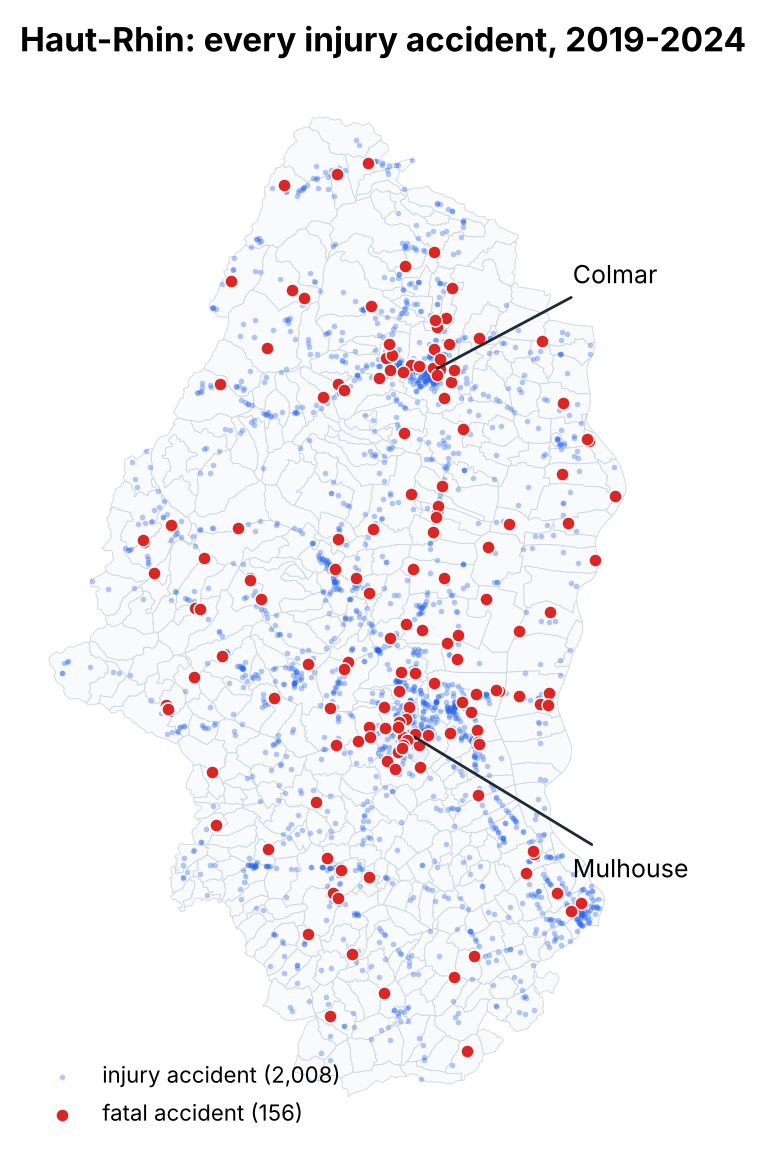

In [14]:
fig_haut_rhin(haut_rhin_points()); Image('../figures/06_haut_rhin_map.png')

### A warning about the denominator
Deaths are almost always recorded; minor accidents are not. Haut-Rhin has a higher *share* of fatal accidents than France, yet fewer deaths per inhabitant: it records fewer non-fatal accidents per inhabitant. The city counts make it visible.

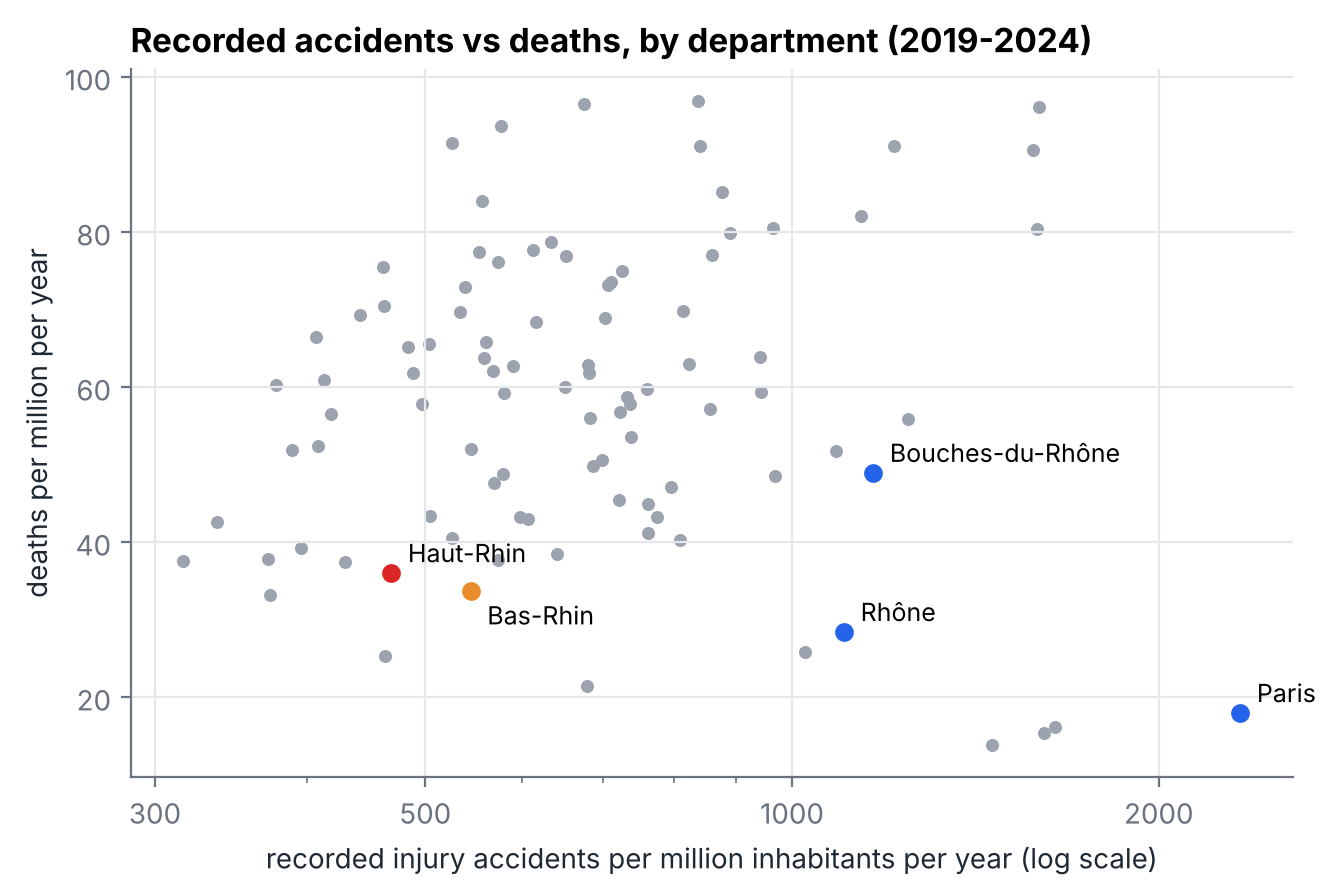

In [15]:
rc = recording_completeness(); fig_completeness(rc); Image('../figures/07_recording_completeness.png')

In [16]:
cities().pivot(index='year', columns='city', values='accidents')

city,Colmar,Mulhouse,Strasbourg
year,,,
2019,48,22,369
2020,20,18,215
2021,31,19,263
2022,24,16,279
2023,19,11,243
2024,24,15,225


Mulhouse records fewer accidents than Colmar, a smaller city, and about 15 times fewer than Strasbourg, which is only about three times its size. That points to under-recording of non-fatal accidents in Mulhouse rather than safer streets, a hypothesis to check with local police or city data.

## 5. What makes an accident fatal?
Logistic regression on ~300,000 accidents. Odds ratios above 1 increase the odds that someone dies; they are associations, not causes.

In [17]:
ors, stats = fit(); stats

{'n_accidents': 301290,
 'fatal_rate': 0.055524577649440736,
 'auc_holdout': 0.7616546574231433,
 'pseudo_r2': 0.108045078390962}

In [18]:
ors.round(2)

,odds_ratio,ci_low,ci_high,p_value
E-scooter involved,0.75,0.64,0.87,0.0
"Rain, snow, fog or wind",0.84,0.80,0.88,0.0
"Night, street lights on",1.09,1.03,1.16,0.0
Weekend,1.17,1.13,1.21,0.0
Dusk or dawn (vs daylight),1.19,1.12,1.27,0.0
"Single vehicle, no collision",1.20,1.15,1.27,0.0
Speed limit 110-130,1.23,1.13,1.35,0.0
Motorcycle involved,1.28,1.23,1.34,0.0
Speed limit 70 (vs <=50),1.52,1.41,1.65,0.0
Bicycle or e-bike involved,1.52,1.43,1.63,0.0


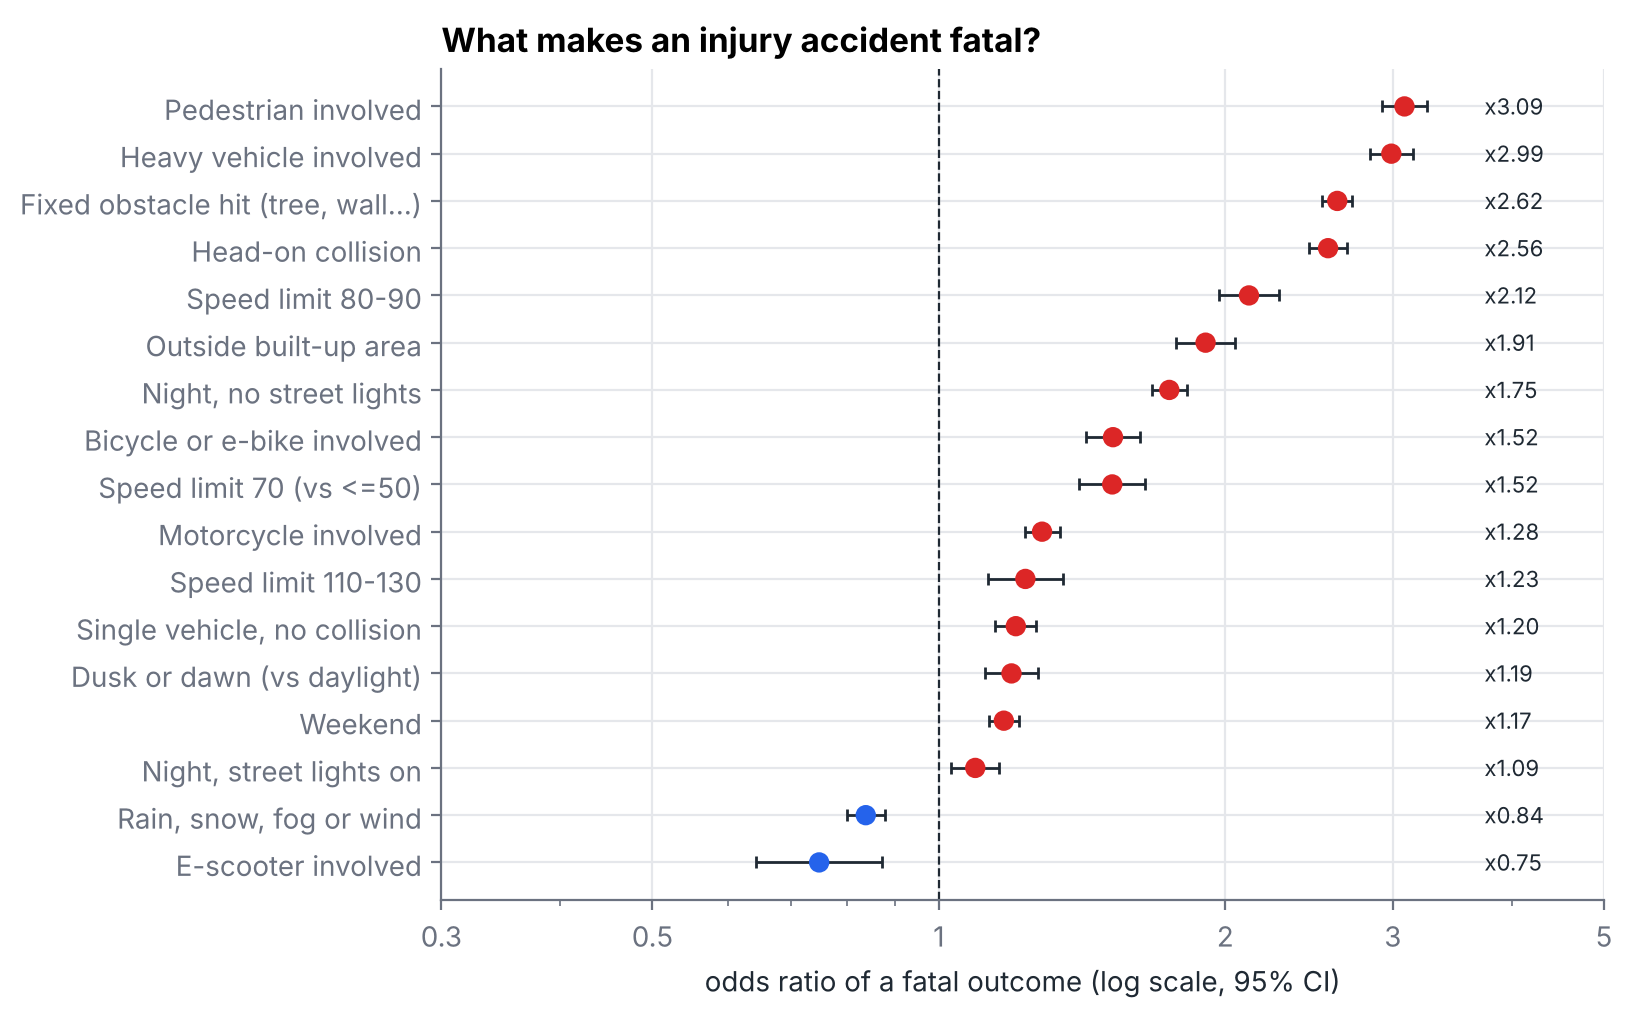

In [19]:
fig_odds(ors); Image('../figures/08_odds_ratios.png')

## Conclusions
* About 3,000 people die every year on metropolitan French roads; the number is flat since 2019.
* Two thirds of deaths happen outside built-up areas, which hold only a third of accidents.
* Deaths of e-scooter riders went from 11 to 47 a year; injured e-scooter users quadrupled.
* Haut-Rhin is among the safer departments (36 deaths per million, rank 11 of 96).
* Pedestrians, heavy vehicles, fixed obstacles and head-on collisions multiply the odds of a fatal outcome by 2.5 to 3.